# Template Clustering Image
load gambar -> scale + PCA -> KMeans -> evaluasi -> plot -> insight

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

## Load data

In [2]:
# # dataset contoh (digits). Kalau soal kasih folder gambar, pakai cell di bawahnya
# from sklearn.datasets import load_digits
# d = load_digits()
# X = d.data
# images = d.images
# y_true = d.target      # label asli, cuma buat ngecek di akhir
# print(X.shape)

In [3]:
# kalau gambar di folder: data/nama_kelas/gambar.jpg
# from pathlib import Path
# from PIL import Image
# paths = sorted(Path("data").rglob("*.jpg"))
# images = np.array([np.array(Image.open(p).convert("RGB").resize((64, 64))) for p in paths])
# X = images.reshape(len(images), -1) / 255.0
# y_true = np.array([p.parent.name for p in paths])

In [4]:
# kalau data .npz (MNIST 100rb): ambil sampel dulu biar ga berat
data = np.load("Image/MNIST_100000_28x28.npz")
images = data["x_train"][:5000]
X = images.reshape(len(images), -1) / 255.0
y_true = data["y_train"][:5000]

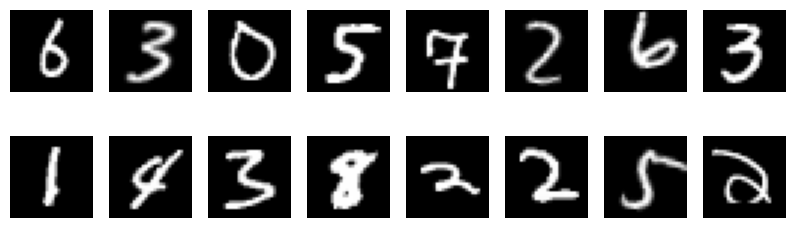

In [5]:
fig, ax = plt.subplots(2, 8, figsize=(10, 3))
for i, a in enumerate(ax.flat):
    a.imshow(images[i], cmap="gray")
    a.axis("off")
plt.show()

## Preprocessing

In [6]:
from sklearn.preprocessing import RobustScaler

X_scaled = RobustScaler().fit_transform(X)  # kalau ada outlier

pca = PCA(n_components=10, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print(pca.explained_variance_ratio_.sum())

0.948040119586066


## Tentukan k

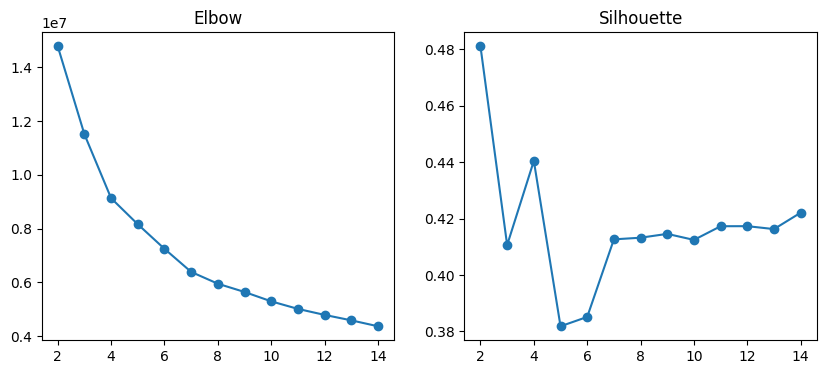

In [7]:
from tqdm.auto import tqdm
ks = range(2, 15)
inertia, sil = [], []
for k in tqdm(ks):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_pca)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_pca, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow")
ax[1].plot(ks, sil, "o-"); ax[1].set_title("Silhouette")
plt.show()

k dipilih = ... karena ... (isi sendiri dari grafik)

## KMeans + evaluasi

In [8]:
k = 10   # GANTI
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_pca)

print("Silhouette    :", silhouette_score(X_pca, labels))
print("Davies-Bouldin:", davies_bouldin_score(X_pca, labels))
print(pd.Series(labels).value_counts().sort_index())

Silhouette    : 0.4124709996071093
Davies-Bouldin: 1.1352480524641781
0    2160
1     225
2     276
3     432
4     328
5     460
6     176
7     322
8     346
9     275
Name: count, dtype: int64


## Plot cluster

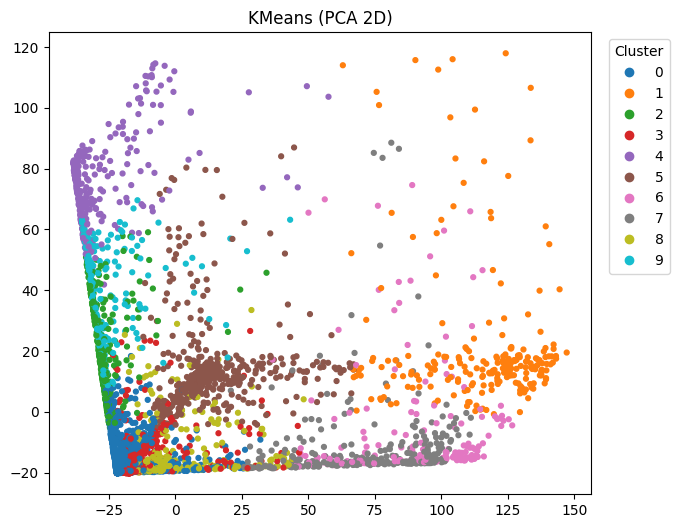

In [9]:
p2 = PCA(n_components=2, random_state=42).fit_transform(X_scaled)

plt.figure(figsize=(7, 6))
sc = plt.scatter(p2[:, 0], p2[:, 1], c=labels, cmap="tab10", s=12)
plt.legend(*sc.legend_elements(), title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.title("KMeans (PCA 2D)")
plt.show()

## Insight tiap cluster

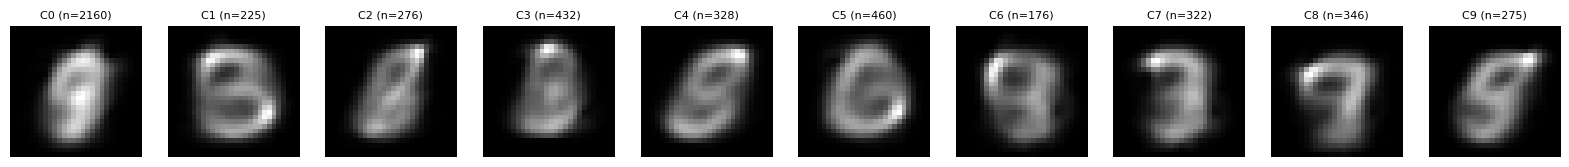

col_0,0,1,2,3,4,5,6,7,8,9
row_0,,,,,,,,,,
0,138,360,89,140,241,174,218,208,231,361
1,35,0,41,67,7,26,25,2,17,5
2,22,50,33,20,49,33,30,0,33,6
3,33,62,97,90,7,20,84,2,31,6
4,66,23,52,37,18,64,10,2,54,2
5,125,1,81,51,19,38,116,6,13,10
6,17,0,10,8,45,10,10,28,26,22
7,1,0,64,84,23,15,5,107,14,9
8,15,1,8,10,34,17,5,150,35,71


In [10]:
fig, ax = plt.subplots(1, k, figsize=(2 * k, 2.5))
for c in range(k):
    mean_img = images[labels == c].mean(axis=0)
    ax[c].imshow(mean_img, cmap="gray")
    ax[c].set_title(f"C{c} (n={np.sum(labels == c)})", fontsize=8)
    ax[c].axis("off")
plt.show()

# bandingin ke label asli kalau ada
pd.crosstab(labels, y_true)

## Kesimpulan
- Evaluasi: silhouette = ..., DBI = ...
- Cluster 0: ...
- Cluster 1: ...
- Cluster yang campur: ...